# INFO 2950-204 Final Project: Phase III
## Weather, Elevation, and Team-Relative Qualifying Pace in Formula 1 (2023–2025)

Richard Ballard (rpb233) · Josephine Kelly (jnk56) · Jason Choi (jc3697) · Orazio Petito (opp2)

**Project repository:** https://github.com/rbllrd/info2950-204_project

**Member contributions (Phase III):**
- **Jason:** Data cleaning notebook (Q1-based relative pace, stable team IDs, wet-Q1 flag, Q1 track temperature); regenerated raw data and analysis-ready dataset.
- **Orazio:** Hypothesis 1 analysis (elevation × team regression, F-test, Mexico City robustness check).
- **Josie:** Hypothesis 2 analysis (temperature × Mercedes regression, permutation test, cloud-cover model).
- **Richard:** Final notebook assembly; introduction, data description, preregistration, limitations, and bibliography; analysis revisions.

## Setup

All data cleaning is done in a separate notebook, [`data_cleaning.ipynb`](https://github.com/rbllrd/info2950-204_project/blob/main/data_cleaning.ipynb), which exports [`analysis_ready.csv`](https://github.com/rbllrd/info2950-204_project/blob/main/analysis_ready.csv). This notebook loads that file directly and performs no further cleaning; it only selects the analysis sample (wet_q1 == False).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 100)      # keep printed tables narrow so they are not cut off in the PDF
pd.set_option("display.max_columns", 10)
pd.set_option("display.precision", 4)

# analysis-ready dataset exported by data_cleaning.ipynb
url = "https://raw.githubusercontent.com/rbllrd/info2950-204_project/main/analysis_ready.csv"
df = pd.read_csv(url)

# wet_q1 is read in as text with missing values; convert it to True/False
df["wet_q1"] = df["wet_q1"].map({True: True, False: False, "True": True, "False": False})
df["is_mercedes"] = df["is_mercedes"].astype(int)  # 1/0 for regression formulas

# primary analysis sample: dry Q1 sessions only (preregistered wet-session rule)
dry = df[df["wet_q1"] == False].copy()

print(f"Full dataset:  {len(df)} team-sessions from {df['session_key'].nunique()} qualifying sessions")
print(f"Wet Q1:        {(df['wet_q1'] == True).sum()} team-sessions "
      f"({df.loc[df['wet_q1'] == True, 'session_key'].nunique()} sessions) excluded")
print(f"Missing flag:  {df['wet_q1'].isna().sum()} team-sessions "
      f"({df.loc[df['wet_q1'].isna(), 'session_key'].nunique()} session) excluded")
print(f"Dry sample:    {len(dry)} team-sessions from {dry['session_key'].nunique()} sessions, "
      f"{dry['team_id'].nunique()} teams")

Full dataset:  878 team-sessions from 88 qualifying sessions
Wet Q1:        90 team-sessions (9 sessions) excluded
Missing flag:  10 team-sessions (1 session) excluded
Dry sample:    778 team-sessions from 78 sessions, 10 teams


Our primary sample keeps only sessions where Q1 was dry (`wet_q1 == False`). Wet sessions change lap times for reasons unrelated to temperature or elevation, so they are excluded from the primary models and used only as a robustness check. One session (2023 Melbourne) has no trackside weather for the Q1 window and is also excluded, since its wet/dry status is unknown.

## Introduction

Formula 1 qualifying sets the starting grid, and small differences in single-lap pace often decide race outcomes. Teams design cars around trade-offs in downforce, cooling, and tyre usage, so conditions that stress those trade-offs, such as thin air at high-altitude circuits or hot track surfaces, may help some teams and hurt others. Altitude reduces downforce and cooling efficiency (Mercedes-AMG Petronas F1 Team, 2021; Williams Racing, 2025), and Mercedes' recent cars have repeatedly been described as struggling to keep their tyres in the right temperature window in hot conditions (Autosport, 2024; F1 Technical, 2024; Cooper, 2025). Whether these effects appear systematically in the data matters to teams choosing set-ups and upgrades, and to analysts and fans who explain results through "car characteristics" after the fact.

**Key terms.** Qualifying has three knockout stages (Q1, Q2, Q3). We measure each team's pace in **Q1**, the only stage every team runs, as the percentage gap between its fastest Q1 lap and the fastest Q1 lap of the session. **Relative pace** is that gap minus the team's average gap for the season, so it measures whether a team was faster (negative) or slower (positive) *than usual*, separating the effect of conditions from overall car strength. Our data combine OpenF1 timing and trackside weather with Open-Meteo historical weather for the 2023–2025 seasons.

**Research questions.**
1. Does circuit elevation affect teams' relative qualifying pace differently?
2. Does Mercedes perform relatively better than usual in cooler conditions?

**Summary of findings.** Under our preregistered tests, we find no statistically significant evidence for either hypothesis. Team-specific elevation effects are not jointly significant under our preregistered F-test (p = 0.184) or a circuit-level permutation test (p = 0.106). Cluster-robust F-tests do reject (p < 0.001), but we treat them as sensitivity checks because they are unreliable with few clusters and all high-altitude variation comes from one circuit (Mexico City). Mercedes' relative pace does not change with track temperature (one-sided p = 0.442). An apparent Mercedes temperature effect in our earlier draft disappears once wet sessions are excluded, consistent with it being driven by wet sessions rather than by temperature: wet sessions are much cooler, and other teams lose far more pace in the wet than Mercedes does (see Hypothesis 2).

## Data Description and Cleaning

Following Gebru et al. (2018):

- **Rows and columns.** Each row is one team in one qualifying session, 2023–2025: **878 rows** from **88 sessions**, including 18 sprint-qualifying sessions flagged by `is_sprint`. Each session has 10 teams except 2024 Zandvoort and 2025 Singapore, where neither Williams driver has an official Q1 time, so Williams is dropped for those sessions under our missing-data rule. Key columns: identifiers (`session_key`, `year`, `circuit_short_name`, `team_id`, `team_name`); performance (`q1_gap_pct`, `q1_relative_pace`, `q1_relative_pace_half`, and the Phase II whole-session `relative_pace`); weather (`track_temp_q1`, `air_temp_f1_q1`, `wet_q1`, `rain_any`, `temperature_2m`, `cloud_cover`); and circuit variables (`elevation_m`, `is_night`, `is_mexico_city`).
- **Why it was created.** We built this dataset to test whether weather and elevation change *team-relative* qualifying pace, not just who is fastest overall.
- **How it was created.** We pulled sessions, drivers, laps, official qualifying results, and minute-level trackside weather from the OpenF1 API (OpenF1, 2026), and hourly weather at each circuit's coordinates from the Open-Meteo Historical Weather API (Zippenfenig, 2023), which is based on the ERA5 reanalysis (Hersbach et al., 2020). Circuit elevations and local time zones were looked up per circuit. All processing used Python (pandas, DuckDB).
- **Who funded it.** OpenF1 is a free, community-run project that republishes Formula 1's live timing feed. Open-Meteo is open source; ERA5 is produced by the European Centre for Medium-Range Weather Forecasts under the EU-funded Copernicus programme.
- **What influenced what was recorded.** OpenF1 coverage begins in 2023, which limits us to three seasons. OpenF1 does not label which laps belong to Q1, so the Q1 weather window is estimated as ending at the last lap set by a driver eliminated in Q1. One session (2023 Melbourne) has no trackside weather for that window. Open-Meteo values are modelled on an ~11–25 km grid at the session-start hour, not measured at the track. Lap times also reflect tyre choices, run plans, and driver errors, which the data do not record.
- **Preprocessing.** See the cleaning steps below.
- **People involved.** Drivers are public figures, and their lap times are broadcast publicly as part of the sport. The dataset contains no private or survey data.
- **Raw data.** Raw API pulls are saved in our repository at [`data/raw/`](https://github.com/rbllrd/info2950-204_project/tree/main/data/raw).

**Data cleaning.** All cleaning is done in [`data_cleaning.ipynb`](https://github.com/rbllrd/info2950-204_project/blob/main/data_cleaning.ipynb), which exports `analysis_ready.csv`. Its steps are:
1. Keep non-cancelled qualifying and sprint-qualifying sessions from 2023–2025.
2. Take each driver's official Q1 time; a team's Q1 time is the faster of its two drivers.
3. Assign drivers to teams by session (handling mid-season transfers) and map rebranded teams to one stable `team_id` (AlphaTauri/RB/Racing Bulls → `racing_bulls`; Alfa Romeo/Kick Sauber → `sauber`).
4. Compute the Q1 gap to the fastest Q1 lap, and keep the Phase II whole-session gap to pole as a secondary measure.
5. Average trackside weather over the estimated Q1 window, and flag sessions with rainfall during Q1 as `wet_q1`.
6. Merge elevation, local start time, and Open-Meteo weather by `session_key`.
7. Compute relative pace against season averages (primary) and half-season averages (robustness, since mid-season upgrades shift a team's baseline).
8. Review the largest gaps. Most occur in wet sessions (e.g., Silverstone 2024, Interlagos 2024, Spa 2023), which is why wet sessions are excluded from our primary models.

**Reliability.** Official Q1 times come from Formula 1's own timing system and are highly reliable; OpenF1 is unofficial but republishes that feed directly. To check our weather sources against each other, the cell below compares OpenF1's trackside air temperature with Open-Meteo's modelled air temperature for every session. Rows are **not independent**: the 10 teams in a session share the same weather and reference lap, and circuits repeat across seasons. We therefore report session-clustered standard errors and permutation tests that shuffle conditions at the session or circuit level.

In [ ]:
# data reliability check: OpenF1 trackside air temperature vs Open-Meteo modelled air temperature, one row per session
s = df.drop_duplicates("session_key").dropna(subset=["air_temp_f1_q1", "temperature_2m"])
diff = s["air_temp_f1_q1"] - s["temperature_2m"]
print(f"Sessions compared: {len(s)}")
print(f"Correlation (OpenF1 air vs Open-Meteo air): {s['air_temp_f1_q1'].corr(s['temperature_2m']):.3f}")
print(f"Mean difference: {diff.mean():+.2f} °C | mean absolute difference: {diff.abs().mean():.2f} °C")
print(f"Correlation (track temp vs OpenF1 air temp): {s['track_temp_q1'].corr(s['air_temp_f1_q1']):.3f}")

Sessions compared: 87
Correlation (OpenF1 air vs Open-Meteo air): 0.964
Mean difference: +0.60 °C | mean absolute difference: 1.14 °C
Correlation (track temp vs OpenF1 air temp): 0.730


The two air-temperature sources agree closely (correlation 0.964 across 87 sessions; mean absolute difference 1.14 °C), so Open-Meteo is a reliable check on the trackside sensors. Track temperature is related to air temperature but far from identical (correlation 0.730), because sun and surface heating raise the track well above the air. Since tyre grip depends on the surface the tyres touch, we use trackside track temperature as our primary temperature measure.

## Preregistration Statements

Both analyses use `q1_relative_pace` as the outcome and the dry-session sample (`wet_q1 == False`; 778 rows, 78 sessions). Sprint-qualifying sessions are included in both analyses. **Controls:** team indicators (Ferrari as reference), and the outcome is centred on each team's season average (computed including wet sessions, which shifts dry-session values slightly below zero), which removes differences in overall car strength. Wet sessions are excluded because rain changes lap times for reasons unrelated to elevation or temperature; we report them only as a robustness check. α = 0.05 throughout.

**Changes from Phase II, in response to feedback.** (1) Our outcome is now based on each team's fastest Q1 lap compared with the fastest Q1 lap, rather than the whole-session gap to pole, which penalised teams eliminated before the faster Q2/Q3 runs. Season averages were recalculated on this measure. (2) Wet-session handling is now stated explicitly. (3) We use stable team IDs across rebrands. (4) Because team-sessions are not independent, we add clustered standard errors and permutation tests. (5) For Statement 2 we test both the Mercedes interaction and Mercedes' own temperature slope. (6) We keep elevation continuous and test robustness by dropping Mexico City rather than splitting at 1,000 m. (7) Our Phase II preregistration used Open-Meteo air temperature; following mentor feedback, our primary measure is now trackside track temperature over the Q1 window, and we report the original air-temperature model as a robustness check.

#### Preregistration Statement 1
**Hypothesis:** Elevation affects teams differently: some teams are relatively faster at high-altitude circuits and others relatively slower.

**Reasoning:** Air density falls with altitude, reducing both downforce and cooling efficiency (Mercedes-AMG Petronas F1 Team, 2021; Williams Racing, 2025). Teams make different design trade-offs in aerodynamic efficiency and cooling, so altitude should not affect every car equally. Either result is informative: a significant effect would identify which designs are altitude-sensitive, while a null result would suggest teams compensate well enough that altitude does not reorder the field.

**Analysis:** Linear regression of relative pace on elevation, team indicators, and elevation × team interactions. We test whether all interactions are jointly zero with an F-test comparing models with and without them, report each team's interaction, and rerun the model without Mexico City, the only circuit above 1,000 m.

#### Preregistration Statement 2
**Hypothesis:** Mercedes performs better than usual (more negative relative pace) when conditions are cooler.

**Reasoning:** Tyres grip best within a narrow temperature window, and Mercedes engineers and drivers have described rear-tyre overheating in hot conditions as a key weakness of their recent cars (Autosport, 2024; F1 Technical, 2024; Cooper, 2025). Testing this tells us whether a widely repeated explanation for Mercedes' results holds up in qualifying data. Our Phase II EDA pointed the other way: Mercedes' mean relative pace was −0.111 (faster than usual) in the warmest third of sessions. That descriptive split did not control for other teams or for wet sessions, so we kept the hypothesis as preregistered and test it formally here.

**Analysis:** Linear regression of relative pace on track temperature, team indicators, and track temperature × Mercedes. We test whether the interaction is greater than zero (Mercedes becoming relatively slower as temperature rises compared with other teams), and whether Mercedes' own slope (temperature + interaction) is greater than zero. As a secondary analysis, we repeat the model with cloud cover instead of temperature for daytime sessions only, since clouds matter little for track heating at night.

## Data Analysis

### Hypothesis 1: Elevation affects teams differently

**Hypothesis:** Elevation affects teams differently: thinner air at high-altitude circuits reduces downforce and cooling, so teams whose cars depend more on these should lose more pace relative to their usual level.

**Model:** `q1_relative_pace ~ elevation × team` (Ferrari as the reference team), fit on dry Q1 sessions. Elevation is measured in kilometres so each coefficient reads as percentage points of relative pace per 1,000 m. An interaction coefficient is how much a team's elevation effect differs from Ferrari's; positive means the team becomes relatively *slower* at altitude.

**Tests:** (1) the preregistered joint F-test of all elevation × team interactions; (2) the same test with session-clustered standard errors, since the 10 teams in a session share one circuit; (3) a permutation test that shuffles elevation across circuits; (4) a rerun without Mexico City. α = 0.05.

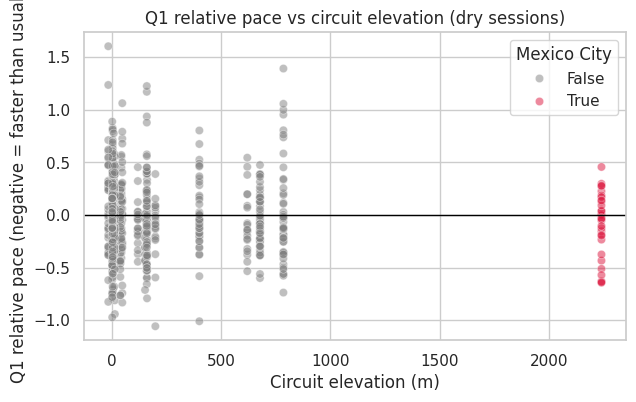

circuit_short_name
Mexico City          2238
Interlagos            785
Spielberg             678
Las Vegas             620
Spa-Francorchamps     401
Name: elevation_m, dtype: int64


In [ ]:
# H1 sample: dry Q1 sessions; elevation rescaled to km so coefficients read "per 1,000 m"
h1 = dry.dropna(subset=["q1_relative_pace", "elevation_m", "team_id"]).copy()
h1["elevation_km"] = h1["elevation_m"] / 1000

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=h1, x="elevation_m", y="q1_relative_pace", hue="is_mexico_city",
                palette={False: "gray", True: "crimson"}, alpha=0.5, ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set(xlabel="Circuit elevation (m)", ylabel="Q1 relative pace (negative = faster than usual)",
       title="Q1 relative pace vs circuit elevation (dry sessions)")
ax.legend(title="Mexico City")
plt.show()
print(h1.groupby("circuit_short_name")["elevation_m"].first().sort_values(ascending=False).head(5))

*Why this figure:* it shows how elevation is distributed across our sessions. Most circuits sit below 800 m and Mexico City (2,238 m) stands far apart, so a small number of sessions supply most of the high-altitude information. No overall trend is visible, which is expected: relative pace is centred within each team-season, and the hypothesis concerns differences *between* teams.

In [ ]:
team = "C(team_id, Treatment(reference='ferrari'))"
clusters = {"groups": h1["session_key"]}

# full model (elevation x team) and reduced model (no interactions)
full = smf.ols(f"q1_relative_pace ~ elevation_km * {team}", data=h1).fit()
reduced = smf.ols(f"q1_relative_pace ~ elevation_km + {team}", data=h1).fit()
full_cl = smf.ols(f"q1_relative_pace ~ elevation_km * {team}", data=h1).fit(
    cov_type="cluster", cov_kwds=clusters)

# (1) preregistered F-test: are all elevation x team interactions jointly zero?
f_classic = anova_lm(reduced, full).iloc[1]

# (2) same joint test with standard errors clustered by session
inter = [n for n in full_cl.params.index if n.startswith("elevation_km:")]
R = np.zeros((len(inter), len(full_cl.params)))
for i, n in enumerate(inter):
    R[i, full_cl.params.index.get_loc(n)] = 1
f_cluster = full_cl.wald_test(R, use_f=True, scalar=True)

print(f"Rows: {int(full.nobs)} | sessions: {h1['session_key'].nunique()} | R-squared: {full.rsquared:.3f}")
print(f"Joint F-test, classical SEs:          F = {f_classic['F']:.2f}, p = {f_classic['Pr(>F)']:.3f}")
print(f"Joint F-test, session-clustered SEs:  F = {float(f_cluster.statistic):.2f}, p = {float(f_cluster.pvalue):.3f}")

Rows: 778 | sessions: 78 | R-squared: 0.023
Joint F-test, classical SEs:          F = 1.40, p = 0.184
Joint F-test, session-clustered SEs:  F = 5.06, p = 0.000


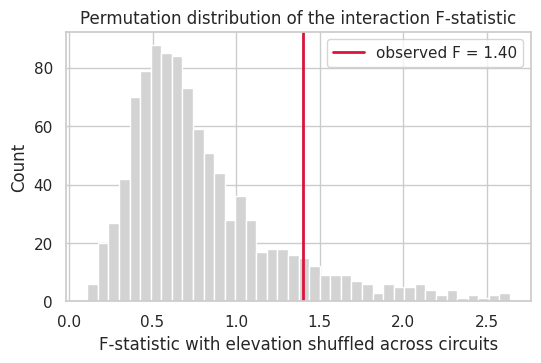

Permutation p-value: 0.106


In [ ]:
# (3) permutation test: shuffle elevation across circuits (elevation is a circuit property), refit, recompute F
rng = np.random.default_rng(2950)
circuits = h1.drop_duplicates("circuit_short_name").set_index("circuit_short_name")["elevation_km"]

def interaction_F(data):
    f = smf.ols(f"q1_relative_pace ~ elevation_km * {team}", data=data).fit()
    r = smf.ols(f"q1_relative_pace ~ elevation_km + {team}", data=data).fit()
    return ((r.ssr - f.ssr) / len(inter)) / (f.ssr / f.df_resid)

F_obs = interaction_F(h1)
perm_F = []
for _ in range(1000):
    shuffled = pd.Series(rng.permutation(circuits.values), index=circuits.index)
    perm_F.append(interaction_F(h1.assign(elevation_km=h1["circuit_short_name"].map(shuffled))))
perm_F = np.array(perm_F)
p_perm_h1 = (perm_F >= F_obs).mean()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(perm_F, bins=40, color="lightgray")
ax.axvline(F_obs, color="crimson", lw=2, label=f"observed F = {F_obs:.2f}")
ax.set(xlabel="F-statistic with elevation shuffled across circuits", ylabel="Count",
       title="Permutation distribution of the interaction F-statistic")
ax.legend()
plt.show()
print(f"Permutation p-value: {p_perm_h1:.3f}")

The preregistered F-test (p = 0.184) and the permutation test (p = 0.106) agree: the elevation × team interactions are not jointly significant. Tests with cluster-robust standard errors disagree sharply, whether clustered by session (p < 0.001, above) or by circuit (p < 0.001, below). We do not base our decision on them. Cluster-robust Wald tests are known to reject too often when there are few clusters (Cameron & Miller, 2015), and the problem is worse here because elevation varies across only 24 circuits and all of the variation above 1,000 m comes from a single circuit (Mexico City, 3 sessions). The permutation test avoids this by shuffling elevation at the circuit level, so we treat it as our primary robustness check.

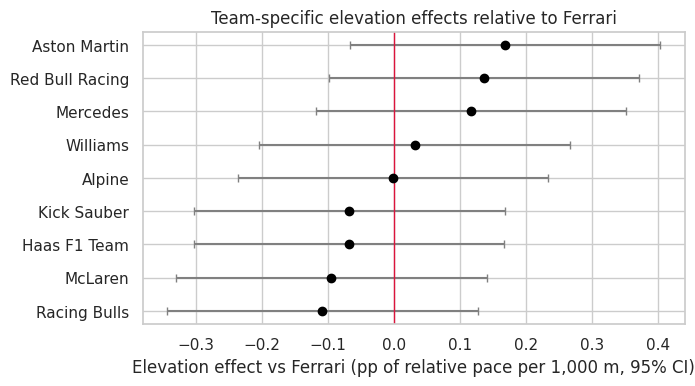

Ferrari (reference) slope: -0.020 pp per 1,000 m (p = 0.817)
Joint F-test, circuit-clustered SEs: F = 10.63, p = 0.0000


,team,diff_vs_ferrari,ci_low,ci_high,p_classical,p_clustered
0,Racing Bulls,-0.109,-0.344,0.127,0.365,0.186
1,McLaren,-0.095,-0.330,0.140,0.429,0.426
2,Haas F1 Team,-0.069,-0.304,0.167,0.568,0.310
3,Kick Sauber,-0.068,-0.303,0.168,0.573,0.484
4,Alpine,-0.002,-0.237,0.234,0.989,0.988
5,Williams,0.031,-0.205,0.267,0.796,0.664
6,Mercedes,0.117,-0.119,0.352,0.330,0.014
7,Red Bull Racing,0.137,-0.099,0.372,0.255,0.118
8,Aston Martin,0.169,-0.067,0.404,0.160,0.001


In [ ]:
# each team's elevation effect compared with Ferrari's, per 1,000 m, with classical and clustered p-values
names = h1.drop_duplicates("team_id").set_index("team_id")["team_name"]
ci = full.conf_int()
h1_table = pd.DataFrame({
    "team": [names[n.split("[T.")[1].rstrip("]")] for n in inter],
    "diff_vs_ferrari": full.params[inter].values,
    "ci_low": ci.loc[inter, 0].values,
    "ci_high": ci.loc[inter, 1].values,
    "p_classical": full.pvalues[inter].values,
    "p_clustered": full_cl.pvalues[inter].values,
}).sort_values("diff_vs_ferrari").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(h1_table["diff_vs_ferrari"], h1_table["team"],
            xerr=[h1_table["diff_vs_ferrari"] - h1_table["ci_low"],
                  h1_table["ci_high"] - h1_table["diff_vs_ferrari"]],
            fmt="o", color="black", ecolor="gray", capsize=3)
ax.axvline(0, color="crimson", lw=1)
ax.set(xlabel="Elevation effect vs Ferrari (pp of relative pace per 1,000 m, 95% CI)", ylabel="",
       title="Team-specific elevation effects relative to Ferrari")
plt.show()

# same joint test clustering by circuit instead of session (24 clusters)
full_circ = smf.ols(f"q1_relative_pace ~ elevation_km * {team}", data=h1).fit(
    cov_type="cluster", cov_kwds={"groups": h1["circuit_short_name"]})
f_circ = full_circ.wald_test(R, use_f=True, scalar=True)
print(f"Ferrari (reference) slope: {full.params['elevation_km']:+.3f} pp per 1,000 m "
      f"(p = {full.pvalues['elevation_km']:.3f})")
print(f"Joint F-test, circuit-clustered SEs: F = {float(f_circ.statistic):.2f}, p = {float(f_circ.pvalue):.4f}")
h1_table.round(3)

The forest plot shows each team’s elevation effect relative to Ferrari with a 95% confidence interval, so the reader can see both the size of each difference and how uncertain it is. Ferrari is the reference team, so its own slope (−0.020 pp per 1,000 m, p = 0.817) is the baseline that every other team is compared against. It is essentially zero, so Ferrari’s relative pace does not change with elevation. Every other team’s interval crosses zero, and the intervals are wide compared with the estimates, so no team’s difference from Ferrari is distinguishable from zero under classical standard errors.

The circuit-clustered joint F-test (F = 10.63, p < 0.001) is shown for completeness. It disagrees with the classical F-test (p = 0.184) and the permutation test (p = 0.106). We do not base our decision on it, because elevation varies across only 24 circuits and all variation above 1,000 m comes from one circuit (Mexico City), which is too few clusters for this test to be reliable (Cameron & Miller, 2015). The table’s p_clustered column shows the same pattern: Mercedes (0.014) and Aston Martin (0.001) fall below 0.05 only under clustered standard errors, so we treat them as exploratory.

In [ ]:
# (4) robustness: same models without Mexico City, the only circuit above 1,000 m
h1_nm = h1[~h1["is_mexico_city"]].copy()
full_nm = smf.ols(f"q1_relative_pace ~ elevation_km * {team}", data=h1_nm).fit()
reduced_nm = smf.ols(f"q1_relative_pace ~ elevation_km + {team}", data=h1_nm).fit()
full_nm_cl = smf.ols(f"q1_relative_pace ~ elevation_km * {team}", data=h1_nm).fit(
    cov_type="cluster", cov_kwds={"groups": h1_nm["session_key"]})

f_classic_nm = anova_lm(reduced_nm, full_nm).iloc[1]
f_cluster_nm = full_nm_cl.wald_test(R, use_f=True, scalar=True)

print(f"Rows: {int(full_nm.nobs)} | sessions: {h1_nm['session_key'].nunique()} | highest circuit: "
      f"{h1_nm['elevation_m'].max():.0f} m")
print(f"Joint F-test, classical SEs:          F = {f_classic_nm['F']:.2f}, p = {f_classic_nm['Pr(>F)']:.3f}")
print(f"Joint F-test, session-clustered SEs:  F = {f_cluster_nm.statistic:.2f}, p = {float(f_cluster_nm.pvalue):.3f}")
print(f"Smallest individual interaction p-value: {full_nm_cl.pvalues[inter].min():.3f}")

Rows: 748 | sessions: 75 | highest circuit: 785 m
Joint F-test, classical SEs:          F = 1.39, p = 0.186
Joint F-test, session-clustered SEs:  F = 2.20, p = 0.031
Smallest individual interaction p-value: 0.088


**Summarizing.** The full model (elevation, team, and their interactions) explains only 2.3% of the variation in relative pace (R² = 0.023). Ferrari's own elevation slope is essentially zero (−0.020 pp per 1,000 m, p = 0.82). Other teams' differences from Ferrari range from −0.109 pp (Racing Bulls) to +0.169 pp (Aston Martin) per 1,000 m, and every 95% confidence interval in the figure includes zero. Under classical standard errors no team interaction is significant (smallest p = 0.160, Aston Martin). Aston Martin and Mercedes fall below 0.05 only with session-clustered standard errors, which we argue above are unreliable here; with nine teams tested, we treat these as exploratory.

**Predicting.** Even the largest estimate is small in practical terms: at Mexico City (2.24 km), Aston Martin would be predicted about 0.38 pp slower relative to its usual level than Ferrari, roughly 0.3 seconds on a 77-second lap.

**Outliers and oddities.** Mexico City is the only circuit above 1,000 m. Removing it leaves the preregistered F-test unchanged (p = 0.186), and no individual interaction remains significant even with clustered standard errors (smallest p = 0.088), so the classical and permutation conclusions do not depend on Mexico City. The session-clustered F-test does change (p < 0.001 to 0.031), consistent with that test being driven by the single high-altitude circuit.

**Decision.** At α = 0.05 we **fail to reject** the null hypothesis that elevation affects all teams equally. The preregistered F-test and the permutation test both find no significant team-specific elevation effects, with or without Mexico City.

### Hypothesis 2: Mercedes performs relatively better in cooler conditions

**Hypothesis:** Mercedes performs better than usual in cooler conditions. Tyres grip best within a narrow temperature window, and Mercedes' recent cars have been reported to overheat their rear tyres in hot conditions (Autosport, 2024; F1 Technical, 2024).

**Model:** `q1_relative_pace ~ track temperature + team + track temperature × Mercedes`, fit on dry Q1 sessions with standard errors clustered by session. The interaction **b2** is how much more Mercedes' relative pace changes per +1 °C than other teams'. We test **H0: b2 = 0** against **H1: b2 > 0** (Mercedes becomes relatively slower as it gets hotter). Following Phase II feedback, we also test Mercedes' *own* temperature slope (temperature + interaction).

**Changes from Phase II:** our primary temperature measure is now OpenF1 trackside temperature averaged over the Q1 window, which is closer to what the tyres experience than Open-Meteo air temperature at the session-start hour. Air temperature is reported as a robustness check. A permutation test and the preregistered daytime cloud-cover model complete the analysis. α = 0.05.

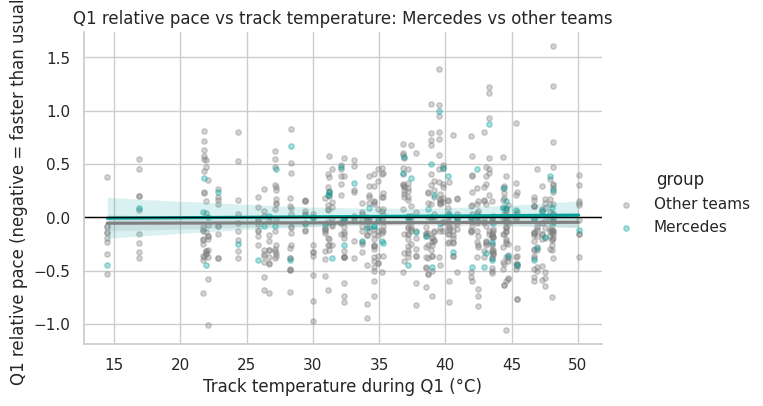

Rows: 778 | sessions: 78 | track temp range: 14.5–50.1 °C


In [ ]:
# H2 sample: dry Q1 sessions with trackside Q1 temperature
h2 = dry.dropna(subset=["q1_relative_pace", "track_temp_q1", "team_id"]).copy()
h2["group"] = np.where(h2["is_mercedes"] == 1, "Mercedes", "Other teams")

g = sns.lmplot(data=h2, x="track_temp_q1", y="q1_relative_pace", hue="group",
               palette={"Mercedes": "#00A19B", "Other teams": "gray"},
               scatter_kws={"alpha": 0.35, "s": 15}, height=4, aspect=1.6)
g.ax.axhline(0, color="black", lw=1)
g.set_axis_labels("Track temperature during Q1 (°C)",
                  "Q1 relative pace (negative = faster than usual)")
g.ax.set_title("Q1 relative pace vs track temperature: Mercedes vs other teams")
plt.show()
print(f"Rows: {len(h2)} | sessions: {h2['session_key'].nunique()} | track temp range: "
      f"{h2['track_temp_q1'].min():.1f}–{h2['track_temp_q1'].max():.1f} °C")

In the figure above, b2 is the difference between the two fitted slopes. If the hypothesis were true, the Mercedes line would rise more steeply than the grey line (slower than usual on hotter tracks). Both lines are nearly flat across a wide temperature range (14.5–50.1 °C), so any difference is small.

In [ ]:
team = "C(team_id, Treatment(reference='ferrari'))"

def fit_h2(data, temp="track_temp_q1", outcome="q1_relative_pace"):
    """relative pace ~ temperature + team + temperature x Mercedes, SEs clustered by session"""
    data = data.dropna(subset=[outcome, temp])
    return smf.ols(f"{outcome} ~ {temp} + {team} + {temp}:is_mercedes", data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["session_key"]})

def one_sided(est, p_two):
    """one-sided p-value for H1: estimate > 0"""
    return p_two / 2 if est > 0 else 1 - p_two / 2

m_h2 = fit_h2(h2)
term = "track_temp_q1:is_mercedes"
b2, p_b2 = m_h2.params[term], one_sided(m_h2.params[term], m_h2.pvalues[term])

# Mercedes' own temperature slope = other teams' slope + interaction
own = m_h2.t_test(f"track_temp_q1 + {term} = 0")
own_est, own_p = float(own.effect[0]), one_sided(float(own.effect[0]), float(own.pvalue))

ci = m_h2.conf_int().loc[term]
print(f"Other teams' slope:   {m_h2.params['track_temp_q1']:+.4f} pp per °C")
print(f"Interaction b2:       {b2:+.4f} pp per °C, 95% CI [{ci[0]:+.4f}, {ci[1]:+.4f}], "
      f"one-sided p = {p_b2:.3f}")
print(f"Mercedes' own slope:  {own_est:+.4f} pp per °C, one-sided p = {own_p:.3f}")

Other teams' slope:   +0.0002 pp per °C
Interaction b2:       +0.0006 pp per °C, 95% CI [-0.0069, +0.0080], one-sided p = 0.442
Mercedes' own slope:  +0.0008 pp per °C, one-sided p = 0.424


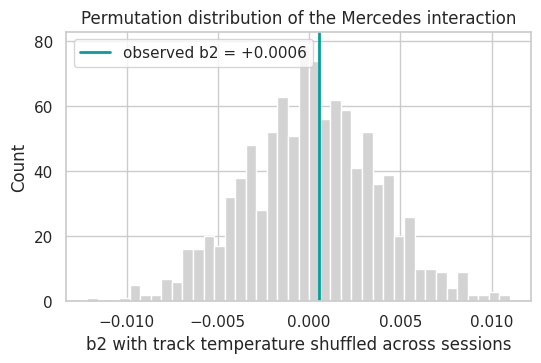

Permutation p-value (one-sided, b2 > 0): 0.446


In [ ]:
# permutation test: shuffle track temperature across sessions (all 10 teams in a session move together)
rng = np.random.default_rng(2950)
sessions = h2.drop_duplicates("session_key")[["session_key", "track_temp_q1"]]
formula = f"q1_relative_pace ~ track_temp_q1 + {team} + {term}"

perm_b2 = []
for _ in range(1000):
    shuffled = sessions.assign(track_temp_q1=rng.permutation(sessions["track_temp_q1"].values))
    d = h2.drop(columns="track_temp_q1").merge(shuffled, on="session_key")
    perm_b2.append(smf.ols(formula, data=d).fit().params[term])
perm_b2 = np.array(perm_b2)
p_perm_h2 = (perm_b2 >= b2).mean()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(perm_b2, bins=40, color="lightgray")
ax.axvline(b2, color="#00A19B", lw=2, label=f"observed b2 = {b2:+.4f}")
ax.set(xlabel="b2 with track temperature shuffled across sessions", ylabel="Count",
       title="Permutation distribution of the Mercedes interaction")
ax.legend()
plt.show()
print(f"Permutation p-value (one-sided, b2 > 0): {p_perm_h2:.3f}")

The interaction is essentially zero (b2 = +0.0006 pp per °C, 95% CI −0.0069 to +0.0080, one-sided p = 0.442), and Mercedes' own temperature slope is also indistinguishable from zero (one-sided p = 0.424). The permutation test, which shuffles temperature at the session level and so makes no assumption about independence within sessions, agrees (p = 0.446): an interaction this large appears in nearly half of the shuffled datasets. This permutation test was not preregistered; we added it as an exploratory check after seeing the regression results, and it does not change the preregistered decision.

In [ ]:
# preregistered secondary analysis: cloud cover instead of temperature, daytime sessions only
day = h2[~h2["is_night"]].copy()
m_cloud = fit_h2(day, temp="cloud_cover")
cterm = "cloud_cover:is_mercedes"
print(f"Daytime rows: {int(m_cloud.nobs)} | sessions: {day['session_key'].nunique()}")
print(f"Cloud x Mercedes: {m_cloud.params[cterm]:+.5f} pp per % cloud "
      f"({10 * m_cloud.params[cterm]:+.4f} per 10%), two-sided p = {m_cloud.pvalues[cterm]:.3f}")

Daytime rows: 589 | sessions: 59
Cloud x Mercedes: +0.00122 pp per % cloud (+0.0122 per 10%), two-sided p = 0.243


In [ ]:
# robustness: re-estimate b2 under alternative choices (all with session-clustered SEs)
checks = [
    ("Primary (track temp, dry)", h2, "track_temp_q1", "q1_relative_pace"),
    ("Air temp, dry", dry, "temperature_2m", "q1_relative_pace"),
    ("Half-season baseline", h2, "track_temp_q1", "q1_relative_pace_half"),
    ("Wet sessions included", df, "track_temp_q1", "q1_relative_pace"),
    ("Phase II setup (wet incl.)", df, "temperature_2m", "relative_pace"),
]
rows = []
for label, data, temp, outcome in checks:
    m = fit_h2(data, temp, outcome)
    t = f"{temp}:is_mercedes"
    rows.append({"specification": label, "n": int(m.nobs), "b2": m.params[t],
                 "p_one_sided": one_sided(m.params[t], m.pvalues[t])})
robust_h2 = pd.DataFrame(rows)
robust_h2.round(4)

,specification,n,b2,p_one_sided
0,"Primary (track temp, dry)",778,0.0006,0.4415
1,"Air temp, dry",778,-0.0089,0.8922
2,Half-season baseline,778,0.0001,0.4915
3,Wet sessions included,868,0.0105,0.0199
4,Phase II setup (wet incl.),868,0.0344,0.0390


                        mean    std  count
group       condition                     
Mercedes    Dry        0.011  0.323     78
            Wet       -0.081  0.343      9
Other teams Dry       -0.049  0.354    700
            Wet        0.412  0.791     81
           mean  count
condition             
Dry        36.7     78
Wet        21.7      9


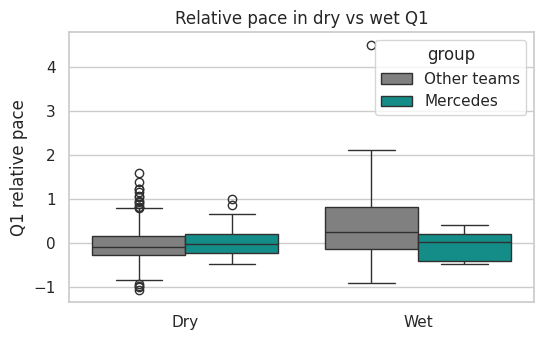

                           coef (pp)  p_two_sided
track_temp_q1:is_mercedes     0.0017       0.6529
wet                           0.4424       0.0170
wet:is_mercedes              -0.5277       0.0119


In [ ]:
# exploratory (not preregistered): why does including wet sessions create a Mercedes temperature effect?
w = df.dropna(subset=["wet_q1", "q1_relative_pace", "track_temp_q1"]).copy()
w["wet"] = w["wet_q1"].astype(int)
w["group"] = np.where(w["is_mercedes"] == 1, "Mercedes", "Other teams")
w["condition"] = np.where(w["wet"] == 1, "Wet", "Dry")

print(w.groupby(["group", "condition"])["q1_relative_pace"].agg(["mean", "std", "count"]).round(3))
print(w.drop_duplicates("session_key").groupby("condition")["track_temp_q1"].agg(["mean", "count"]).round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=w, x="condition", y="q1_relative_pace", hue="group",
            palette={"Mercedes": "#00A19B", "Other teams": "gray"}, ax=ax)
ax.set(xlabel="", ylabel="Q1 relative pace", title="Relative pace in dry vs wet Q1")
plt.show()

m_wet = smf.ols(f"q1_relative_pace ~ track_temp_q1 + {team} + track_temp_q1:is_mercedes"
                " + wet + wet:is_mercedes", data=w).fit(
    cov_type="cluster", cov_kwds={"groups": w["session_key"]})
print(pd.DataFrame({"coef (pp)": m_wet.params[["track_temp_q1:is_mercedes", "wet", "wet:is_mercedes"]],
                    "p_two_sided": m_wet.pvalues[["track_temp_q1:is_mercedes", "wet", "wet:is_mercedes"]]}).round(4))

The figure above compares relative pace in dry and wet Q1 for Mercedes and the other teams, to test why including wet sessions made the Mercedes hypothesis look supported. In dry sessions the two groups are close (Mercedes +0.011, others −0.049). In wet sessions the other teams are much slower than usual (+0.412) while Mercedes is not (−0.081), and wet sessions are far cooler (21.7 °C vs 36.7 °C). Mercedes therefore appears to do relatively better in cool conditions only when wet sessions are included.

In [ ]:
# predicted relative pace for Mercedes and Ferrari at a cool vs hot session (10th / 90th percentile)
cool, hot = h2["track_temp_q1"].quantile([0.10, 0.90])
grid = pd.DataFrame({"team_id": ["mercedes", "mercedes", "ferrari", "ferrari"],
                     "is_mercedes": [1, 1, 0, 0], "track_temp_q1": [cool, hot, cool, hot]})
grid["predicted_pace"] = m_h2.predict(grid)
print(f"Cool session = {cool:.1f} °C, hot session = {hot:.1f} °C")
grid.round(3)

Cool session = 24.3 °C, hot session = 46.9 °C


,team_id,is_mercedes,track_temp_q1,predicted_pace
0,mercedes,1,24.317,0.001
1,mercedes,1,46.884,0.019
2,ferrari,0,24.317,-0.065
3,ferrari,0,46.884,-0.059


**Summarizing.** In dry sessions, track temperature explains almost none of the variation in relative pace, for Mercedes or anyone else. The Mercedes interaction (b2 = +0.0006 pp per °C) and Mercedes' own slope (+0.0008 pp per °C) are both close to zero. The preregistered daytime cloud-cover model also shows no effect (+0.012 pp per 10% cloud, two-sided p = 0.243), and its sign is opposite to the cooling explanation, which predicts a negative coefficient.

**Predicting.** Moving from a cool session (24.3 °C) to a hot one (46.9 °C), Mercedes' predicted relative pace changes by only +0.018 pp, versus +0.006 pp for Ferrari: about 0.01 seconds on a 90-second lap.

**Outliers and oddities.** The robustness table shows the result holds with air temperature and with a half-season baseline. It changes only when wet sessions are included (p = 0.020), and the Phase II setup (whole-session pace, air temperature, wet sessions included) reproduces the apparent effect from our earlier draft (p = 0.039). Wet sessions are much cooler (mean track temperature 21.7 °C across 9 wet sessions vs 36.7 °C across 78 dry ones), and the other nine teams lose far more pace in the wet than Mercedes does (mean relative pace +0.412 vs −0.081; wet × Mercedes = −0.528 pp). Mercedes therefore looks relatively better in cool, wet sessions, which produces the apparent cooling effect. When we add wet and wet × Mercedes terms, the temperature interaction falls from +0.0105 to +0.0017 pp per °C (two-sided p = 0.653). This is consistent with the earlier effect coming from wet sessions rather than tyre temperature, and supports excluding them.

**Decision.** At α = 0.05 we **fail to reject** H0 for both the interaction (p = 0.442; permutation p = 0.446) and Mercedes' own slope (p = 0.424). We find no evidence that Mercedes performs relatively better in cooler conditions.

## Evaluation of Significance

In [ ]:
# every preregistered test and robustness check in one table
def decide(p):
    return "Reject H0" if p < 0.05 else "Fail to reject"

sig = pd.DataFrame([
    ("H1", "F-test, classical (prereg.)", f_classic["F"], f_classic["Pr(>F)"]),
    ("H1", "F-test, clustered SEs*", float(f_cluster.statistic), float(f_cluster.pvalue)),
    ("H1", "Permutation (circuits)", F_obs, p_perm_h1),
    ("H1", "F-test, no Mexico City", f_classic_nm["F"], f_classic_nm["Pr(>F)"]),
    ("H2", "b2 > 0, clustered", b2, p_b2),
    ("H2", "Mercedes own slope > 0", own_est, own_p),
    ("H2", "Permutation (sessions)", b2, p_perm_h2),
    ("H2", "Cloud x Mercedes, day", m_cloud.params[cterm], m_cloud.pvalues[cterm]),
], columns=["hyp", "test", "estimate", "p_value"])
sig["decision"] = sig["p_value"].apply(decide)
sig.round(4)

,hyp,test,estimate,p_value,decision
0,H1,"F-test, classical (prereg.)",1.4002,0.1838,Fail to reject
1,H1,"F-test, clustered SEs*",5.0639,0.0000,Reject H0
2,H1,Permutation (circuits),1.4002,0.1060,Fail to reject
3,H1,"F-test, no Mexico City",1.3945,0.1864,Fail to reject
4,H2,"b2 > 0, clustered",0.0006,0.4415,Fail to reject
5,H2,Mercedes own slope > 0,0.0008,0.4242,Fail to reject
6,H2,Permutation (sessions),0.0006,0.4460,Fail to reject
7,H2,"Cloud x Mercedes, day",0.0012,0.2427,Fail to reject


A p-value is the probability of an estimate at least this extreme if the null hypothesis were true; we reject H0 when p < 0.05.

**Hypothesis 1 (elevation × team).** The preregistered F-test (p = 0.184), the circuit-level permutation test (p = 0.106), and the rerun without Mexico City (p = 0.186) all fail to reject H0. *Only the cluster-robust F-tests reject (session-clustered p < 0.001; circuit-clustered p < 0.001). We do not base our decision on them: cluster-robust Wald tests over-reject when clusters are few (Cameron & Miller, 2015), and here all high-altitude variation comes from one circuit. The session-clustered p-value rises from < 0.001 to 0.031 once Mexico City is removed, so that test's rejection depends heavily on this one circuit. We therefore **fail to reject H0**: there is no reliable evidence that elevation affects teams differently.

**Hypothesis 2 (Mercedes × temperature).** All tests agree. The interaction (one-sided p = 0.442), Mercedes' own slope (p = 0.424), and the session-level permutation test (p = 0.446) are far from significant, as is the daytime cloud-cover model (p = 0.243). We **fail to reject H0**. The only specifications that reach significance include wet sessions (p = 0.020 and 0.039; see the robustness table), which we excluded in advance because rain changes lap times for reasons unrelated to temperature; the wet-versus-dry comparison in Hypothesis 2 shows that Mercedes' pace relative to other teams differs sharply in the wet.

These findings matter even though they are null: they show that two common explanations for qualifying results, "altitude suits some cars" and "Mercedes is quicker when it's cool," do not hold up once conditions are measured carefully and wet sessions are separated out.

## Conclusions

**RQ1: Does elevation affect teams' relative qualifying pace differently?** No reliable evidence. The full elevation model explains only about 2% of the variation in relative pace, team-specific elevation effects are not jointly significant under either the preregistered F-test or the permutation test, and results do not change when Mexico City is removed. Even the largest team difference (Aston Martin, +0.17 pp per 1,000 m) amounts to roughly 0.3 seconds per lap at Mexico City, the highest circuit on the calendar.

**RQ2: Does Mercedes perform relatively better in cooler conditions?** No. In dry sessions, Mercedes' relative pace is essentially flat across a 14.5–50.1 °C range of track temperatures, and its temperature sensitivity is indistinguishable from other teams' (b2 = +0.0006 pp per °C, p = 0.442). Cloud cover shows no effect either.

**Overall.** Once overall car strength is removed by measuring pace relative to each team's own season average, weather and elevation show little systematic association with how teams perform in qualifying. A key methodological finding is that including wet sessions made the Mercedes hypothesis look supported (p = 0.039), while excluding them removed the effect. Wet sessions are much cooler, and Mercedes loses less pace in the wet than other teams (wet × Mercedes = −0.528 pp); controlling for this drops the temperature interaction to +0.0017 pp per °C. This is consistent with wet sessions, not tyre temperature, producing the effect, though with only 9 wet sessions we treat it as a caution rather than a proven mechanism.

## Limitations

- **Few independent observations.** Our 778 dry rows come from only 78 sessions and 24 circuits, with a single high-altitude circuit (3 sessions). This limits statistical power: a "fail to reject" means we found no evidence of an effect, not evidence that no effect exists, and small team-specific effects could go undetected.
- **What Q1 lap times capture.** A team's fastest Q1 lap also reflects driver skill and errors, tyre choices, traffic, and track evolution, none of which we observe. Strong teams sometimes do only what is needed to advance from Q1, which adds noise to their measured pace.
- **Weather measurement.** The Q1 window is estimated from lap timing, one session lacks trackside weather, and Open-Meteo values are modelled estimates on an 11–25 km grid. Averaging track temperature over Q1 also hides changes within the session. Humidity and wind are not modelled.
- **Changing baselines and limited scope.** Season averages assume a stable car, but teams upgrade during the season; our half-season check gives the same result, but upgrades between races remain a source of noise. Our three seasons cover one set of technical regulations, so results may not generalize to other eras such as the new 2026 regulations.
- **Confounding with circuits.** Temperature and elevation are tied to specific circuits, which also differ in layout and surface. An apparent condition effect could reflect circuit characteristics, and vice versa.
- **Limitations of our significance tests.** We ran many tests (8 summary tests plus 9 individual team interactions), which raises the chance that some p-value falls below 0.05 by chance. Cluster-robust standard errors are unreliable when variation comes from few clusters, as seen in Hypothesis 1, and permutation tests assume conditions are exchangeable across sessions, which circuit differences may violate.
- **Potential harms.** The data concern public sporting results and pose little direct risk to individuals. The main harm is overclaiming: presenting weak or spurious patterns (such as our wet-session result) as evidence about a team's or driver's ability could mislead fans, media coverage, or betting and fantasy decisions.

## Acknowledgements and Bibliography

**Data and literature**

1. Autosport. (2024). *Mercedes still chasing answer for tyre temperature factor – Shovlin*. https://www.autosport.com/f1/news/mercedes-still-chasing-answer-for-tyre-temperature-factor-shovlin/10644411/
2. Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372.
3. Cooper, S. (2025). *Russell tells Mercedes to 'think quick' with 'baked in' W16 weakness concern*. PlanetF1. https://www.planetf1.com/news/george-russell-mercedes-think-quick-baked-in-weakness-concern
4. F1 Technical. (2024). *Mercedes pinpoints tyre temperatures as main limitation*. https://www.f1technical.net/news/24470
5. Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2018). *Datasheets for datasets*. arXiv:1803.09010. https://arxiv.org/abs/1803.09010
6. Hersbach, H., Bell, B., Berrisford, P., et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society, 146*(730), 1999–2049. https://doi.org/10.1002/qj.3803
7. Mercedes-AMG PETRONAS F1 Team. (2021). *What impact does high altitude have on an F1 car?* https://www.mercedesamgf1.com/news/what-impact-does-high-altitude-have-on-an-f1-car
8. OpenF1. (2026). *OpenF1 API documentation*. https://openf1.org/docs/
9. Williams Racing. (2025). *What are the challenges of racing at altitude?* https://williamsf1.com/posts/1b7fa31b-4bbc-406e-b146-fe517cdcbd2f/what-are-the-challenges-of-racing-at-altitude
10. Zippenfenig, P. (2023). *Open-Meteo.com Weather API* [Computer software]. Zenodo. https://doi.org/10.5281/zenodo.7970649

**Software**

11. Harris, C. R., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362.
12. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95.
13. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
14. Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. *Proceedings of SIGMOD 2019*, 1981–1984.
15. Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96.
16. Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021.

**Acknowledgements.** We thank our section mentor, Jingruo Chen, and our Phase II peer reviewers for feedback that shaped our revised outcome measure and wet-session handling, and the INFO 2950 course staff for lecture materials on regression and permutation testing. Project code and data: https://github.com/rbllrd/info2950-204_project

## Questions for Reviewers

1. For Hypothesis 1, both session- and circuit-clustered F-tests reject, while the preregistered F-test and the circuit-level permutation test do not. We rely on the permutation test because cluster-robust tests over-reject with few clusters. Is this reasoning sound, or would a wild cluster bootstrap be a better check for Phase IV?
2. Both hypotheses returned null results. For Phase IV, would it be more valuable to deepen these analyses (e.g., test every team's temperature sensitivity, not only Mercedes') or to examine wet sessions directly as their own question?
3. We estimate the end of Q1 from the last lap set by a driver eliminated in Q1. Is this approximation reasonable for matching weather to Q1, or should we use a different source such as race-control messages?
4. Our permutation test for Hypothesis 2 was not preregistered; we added it after seeing that the regression results did not match our hypothesis. Should exploratory checks like this be kept in the report if clearly labeled, or left out? And is there an analysis you would recommend (e.g., splitting by season, testing a temperature threshold, or using race-stint pace instead of single-lap qualifying pace) to identify conditions under which our hypothesis might hold?